# Exploratory Data Analysis: California Wildfires, 2016–2020

Run `data_cleaning.ipynb` first. Every figure is saved to `figures/`.

In [24]:
import sys; sys.path.append("..")
from src.labels import pretty
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load, feature_sets, cv_folds, WEATHER

df = load()
sets = feature_sets(df)
order = sorted(df["TARGET"].unique())
df["LARGE"] = df["TARGET"].isin(["D-E", "F-G"])     # 100+ acres (class D and up)

FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
def save(name):
    plt.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")

print(df.shape)
print(df["FIRE_YEAR"].value_counts().sort_index())

(43561, 97)
FIRE_YEAR
2016     7882
2017     9537
2018     9488
2019     6454
2020    10200
Name: count, dtype: int64


## 1. How imbalanced is the target?

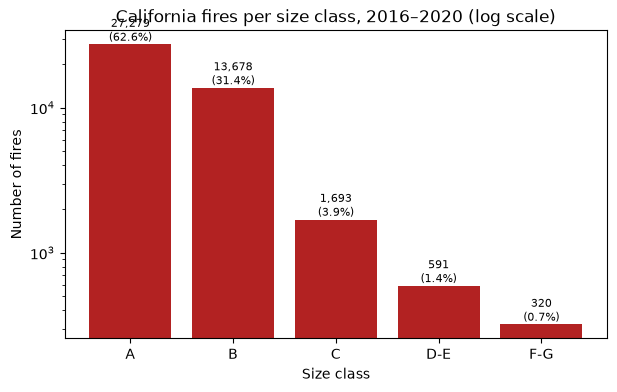

In [25]:
counts = df["TARGET"].value_counts().reindex(order)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(order, counts, color="firebrick")
ax.set_yscale("log")
ax.set(title="California fires per size class, 2016–2020 (log scale)", xlabel="Size class", ylabel="Number of fires")
for b, v in zip(bars, counts):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom", fontsize=8)
save("01_class_imbalance"); plt.show()

**Notes:** 62.6% of wildfires in California (2016-2020) were class A, meaning the total acreage burned was 0.25 acre or less. Bigger fires are less common, with classes F-G making up only 0.7% of the data. Class F-G represents 1000-5000+ acres burned.

## 2. Where do fires happen, and where are the large ones?

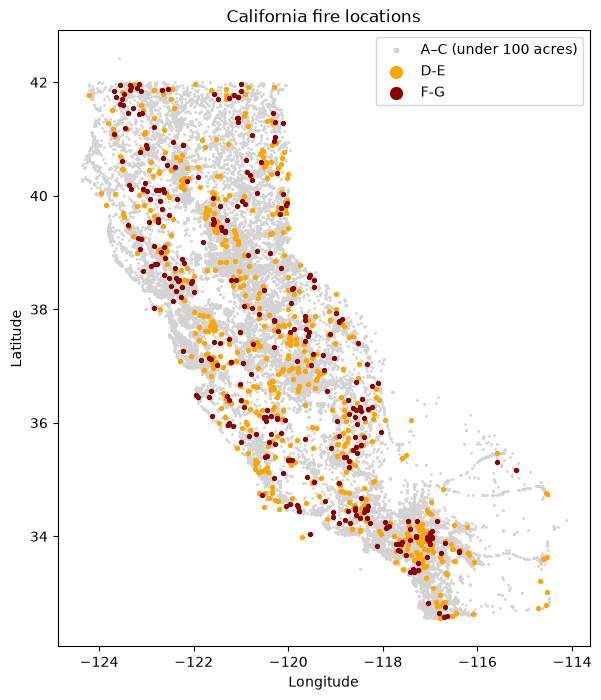

In [26]:
fig, ax = plt.subplots(figsize=(7, 8))
small = df[~df["LARGE"]]
ax.scatter(small["LONGITUDE"], small["LATITUDE"], s=1, c="lightgray", label="A–C (under 100 acres)")
colors = {"D-E": "orange", "F-G": "darkred"}
for cls in ["D-E", "F-G"]:
    s = df[df["TARGET"] == cls]
    ax.scatter(s["LONGITUDE"], s["LATITUDE"], s=8, c=colors[cls], label=cls)
ax.set(title="California fire locations", xlabel="Longitude", ylabel="Latitude")
ax.set_aspect(1.2)
ax.legend(markerscale=3, loc="upper right")
save("02_fire_map"); plt.show()

**Notes:** Southern California (around −117.5, 34) has the densest group of large fires, mostly D-E (orange). But it also has the densest gray: there are simply many more fires there overall. A large share of California's population lives in this region, which could account for more ignitions.

Northern California (the Klamath and North Coast ranges, upper left) has proportionally more F-G (dark red) than orange. Fewer fires start there, but the ones that do tend to get very big. These are more remote, forested areas where fires are harder to reach quickly.

## 3. The location split: which regions land in which fold?

**Folds / cross-validation:** We split the data into 5 location-based folds, then train 5 times, each time testing on a different fold the model hasn't seen. Every fire gets tested once, and we report the average score ± spread across the 5 rounds.

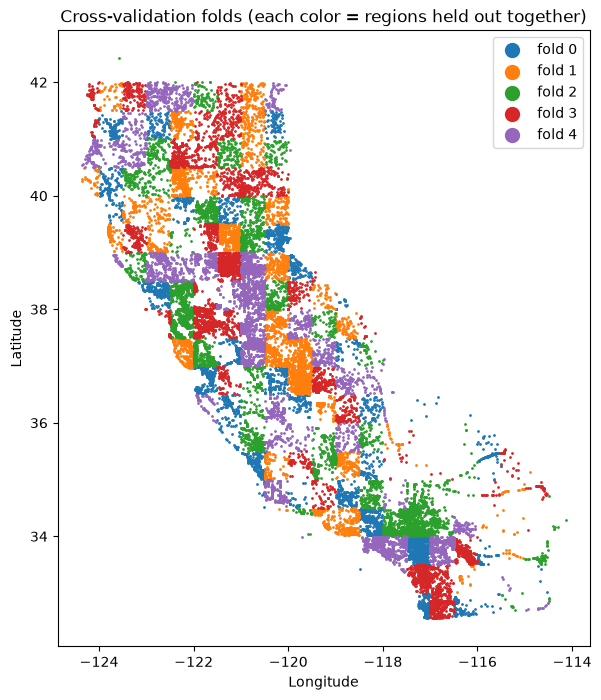

FOLD,0,1,2,3,4,All
TARGET,,,,,,
A,5581,5467,5499,5395,5337,27279
B,2667,2692,2688,2795,2836,13678
C,290,366,346,341,350,1693
D-E,125,123,115,116,112,591
F-G,50,64,64,65,77,320
All,8713,8712,8712,8712,8712,43561


In [27]:
df["FOLD"] = -1
for i, (tr, te) in enumerate(cv_folds(df)):
    df.loc[te.index, "FOLD"] = i

fig, ax = plt.subplots(figsize=(7, 8))
for i in sorted(df["FOLD"].unique()):
    s = df[df["FOLD"] == i]
    ax.scatter(s["LONGITUDE"], s["LATITUDE"], s=1, label=f"fold {i}")
ax.set(title="Cross-validation folds (each color = regions held out together)", xlabel="Longitude", ylabel="Latitude")
ax.set_aspect(1.2)
ax.legend(markerscale=10)
save("03_cv_folds_map"); plt.show()

pd.crosstab(df["TARGET"], df["FOLD"], margins=True)

**Notes:** The folds are balanced, with each one holding about 8712 fires and class A representing about 63% of each one. No fold is missing a class, so all classes can be evaluated in every fold.

Limitation: fires near block borders may still resemble neighbors in other folds.

## 4. Do conditions differ between small and large fires?

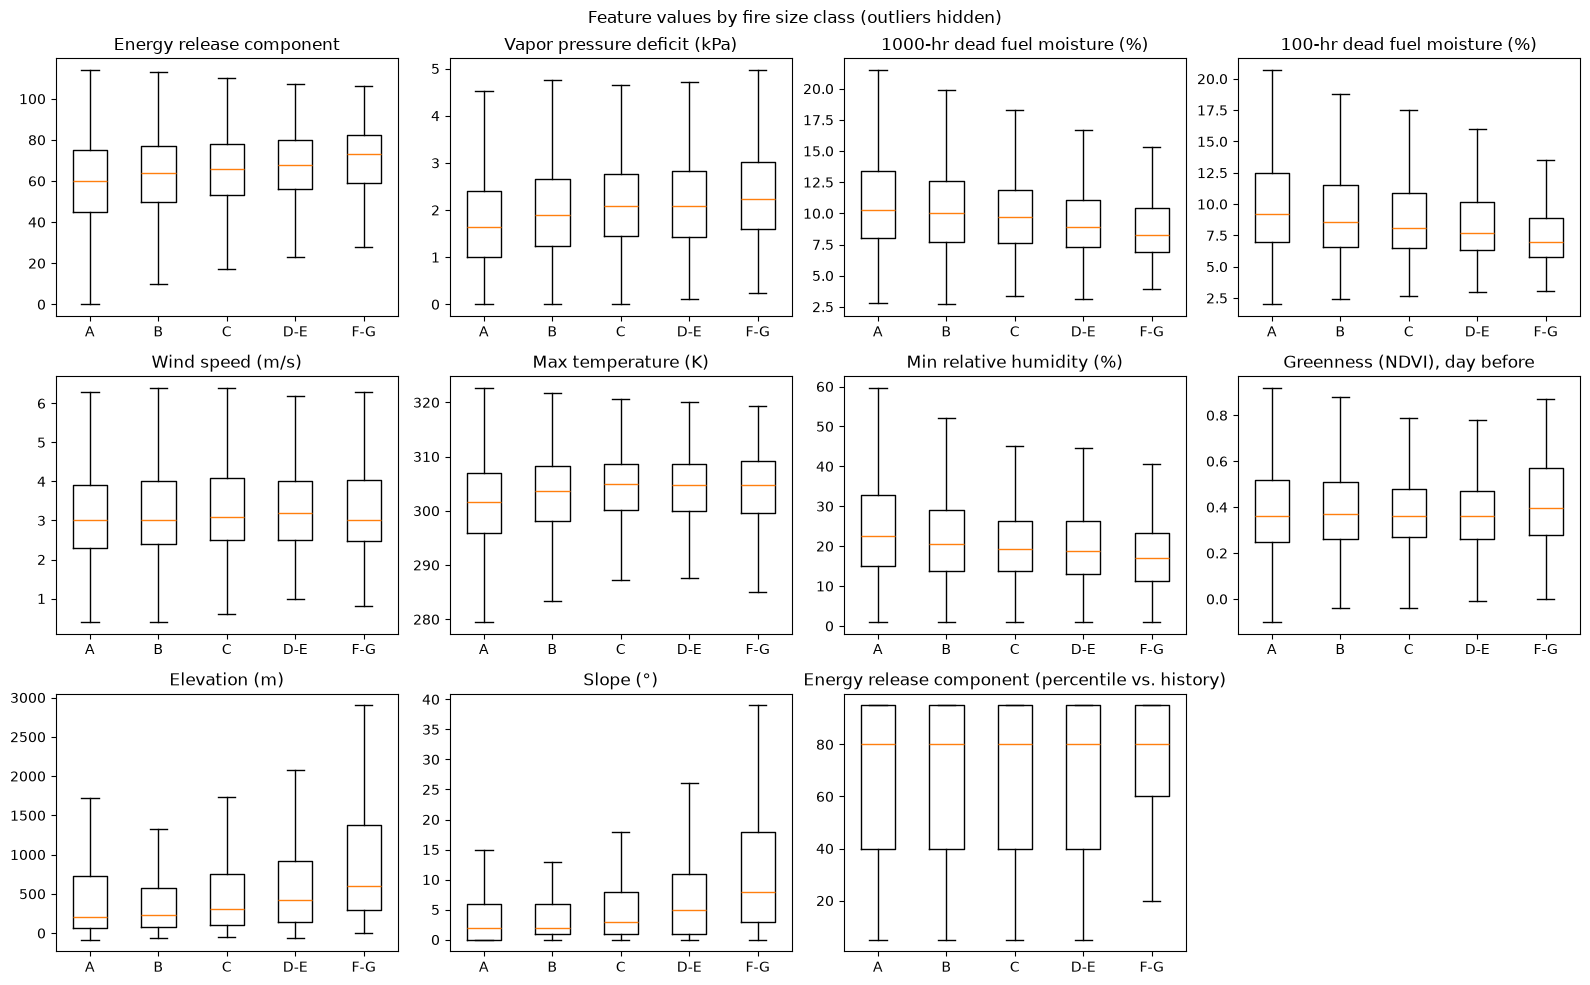

TARGET,A,B,C,D-E,F-G
Energy release component,60.00,64.00,66.00,68.00,73.00
Vapor pressure deficit (kPa),1.64,1.90,2.09,2.09,2.23
1000-hr dead fuel moisture (%),10.30,10.00,9.70,8.90,8.30
100-hr dead fuel moisture (%),9.20,8.60,8.10,7.70,7.00
Wind speed (m/s),3.00,3.00,3.10,3.20,3.00
Max temperature (K),301.60,303.70,304.90,304.70,304.70
Min relative humidity (%),22.60,20.60,19.20,18.90,16.95
"Greenness (NDVI), day before",0.36,0.37,0.36,0.36,0.40
Elevation (m),211.00,235.00,304.00,421.00,601.00
Slope (°),2.00,2.00,3.00,5.00,8.00


In [28]:
feats = ["erc", "vpd", "fm1000", "fm100", "vs", "tmmx", "rmin", "NDVI-1day", "CheatGrass", "Elevation", "Slope", "erc_Percentile"]
feats = [f for f in feats if f in df.columns]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, f in zip(axes.flat, feats):
    data = [df.loc[df["TARGET"] == c, f].dropna() for c in order]
    ax.boxplot(data, tick_labels=order, showfliers=False)
    ax.set_title(pretty(f))
for ax in axes.flat[len(feats):]:
    ax.axis("off")
plt.suptitle("Feature values by fire size class (outliers hidden)")
plt.tight_layout()
save("04_features_by_class"); plt.show()

# The same idea as numbers: median of each feature per class
df.groupby("TARGET")[feats].median().round(2).rename(columns=pretty).T

**Notes:** Larger fires start under drier conditions. From class A to F-G, the energy release component (how much energy the fuels can release) rises from 60 to 73, and vapor pressure deficit (how strongly the air pulls moisture from plants) rises from 1.6 to 2.2 kPa. 100-hour and 1000-hour dead fuel moisture (moisture in dead branches and logs) and minimum relative humidity all fall. Larger fires also happen at higher elevations and on steeper slopes, consistent with remote, rugged terrain where fire spreads uphill and crews are slower to arrive. Max temperature rises from class A to C, then levels off (~302→305 K, about 83→89°F). Wind speed shows no trend, likely because it is a daily average over a ~4 km area on the ignition day only and misses gusts and later wind events. Vegetation greenness (NDVI) shows little difference between classes. Cheatgrass cover used 255 as a "no data" code that appeared mostly for small fires, which would leak information, so it was [checked/removed].

## 5. Seasonality: when do large fires happen?

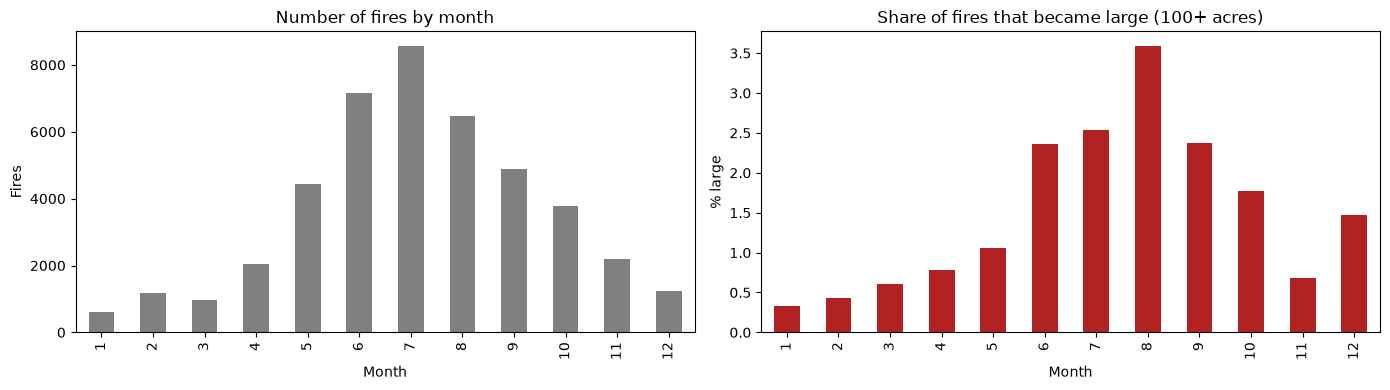

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df["DISCOVERY_MONTH"].value_counts().sort_index().plot.bar(ax=axes[0], color="gray")
axes[0].set(title="Number of fires by month", xlabel="Month", ylabel="Fires")

(df.groupby("DISCOVERY_MONTH")["LARGE"].mean() * 100).plot.bar(ax=axes[1], color="firebrick")
axes[1].set(title="Share of fires that became large (100+ acres)", xlabel="Month", ylabel="% large")

plt.tight_layout()
save("05_seasonality"); plt.show()

**Notes:** Wildfires follow a clear seasonal cycle. July has the most fires (8000+), but August has the highest share that become large (~3.6% reach 100+ acres), as fuels are driest late in the summer. December has a small secondary bump in large fires (~1.5%), possibly linked to fall and winter Santa Ana wind events in Southern California.

## 6. Vegetation: which land cover types produce large fires?

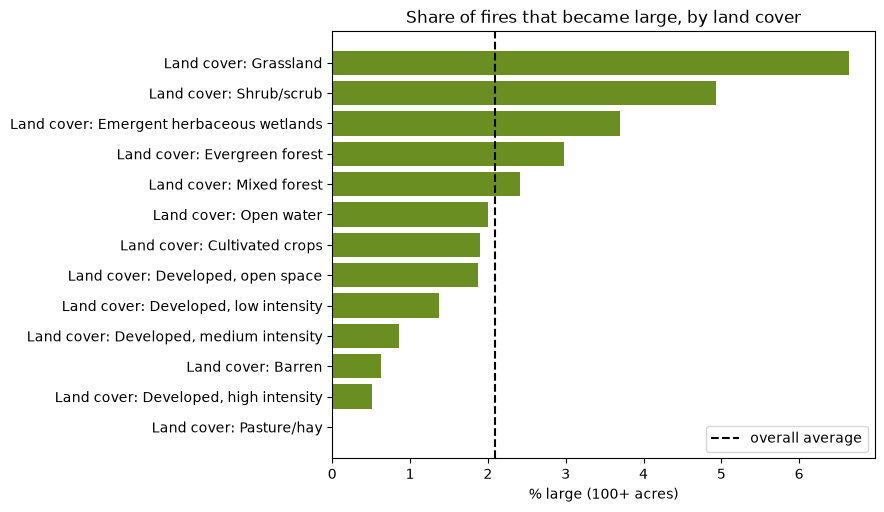

,fires,% large
Land cover: Pasture/hay,153,0.0
"Land cover: Developed, high intensity",3678,0.5
Land cover: Barren,160,0.6
"Land cover: Developed, medium intensity",11089,0.9
"Land cover: Developed, low intensity",7776,1.4
"Land cover: Developed, open space",8112,1.9
Land cover: Cultivated crops,951,1.9
Land cover: Open water,150,2.0
Land cover: Mixed forest,332,2.4
Land cover: Evergreen forest,4098,3.0


In [30]:
lc_cols = [c for c in df.columns if c.startswith("LC_")]
lc = pd.DataFrame({
    "fires": [int(df[c].sum()) for c in lc_cols],
    "% large": [df.loc[df[c] == 1, "LARGE"].mean() * 100 for c in lc_cols],
}, index=lc_cols)
lc = lc[lc["fires"] >= 100].sort_values("% large")   # skip tiny categories
lc.index = [pretty(c) for c in lc.index]              #readable names for bars and table

fig, ax = plt.subplots(figsize=(7, 0.35 * len(lc) + 1))
ax.barh(lc.index, lc["% large"], color="olivedrab")
ax.axvline(df["LARGE"].mean() * 100, color="k", ls="--", label="overall average")
ax.set(title="Share of fires that became large, by land cover", xlabel="% large (100+ acres)")   
ax.legend()
save("06_landcover_large_share"); plt.show()
lc.round(1)

**Notes:** **Land cover (NLCD codes):** Fires in grassland and shrub/scrub are most likely to become large (~6.6% and ~4.9%, versus a ~2.1% average), followed by emergent herbaceous wetlands and evergreen forest. Grass and brush dry quickly and let fire spread fast, so they burn more acres than forests, even though forest fires may be more severe. Developed land shows a clear gradient: the more built-up the area, the less likely a fire becomes large.

## 7. Slope direction: do south-facing slopes produce more large fires?

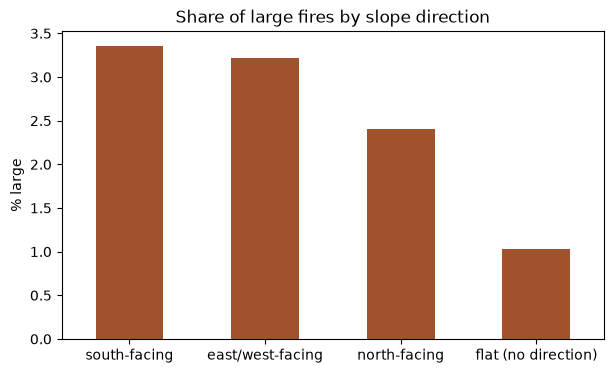

                     % large  fires
Aspect_cos                         
south-facing            3.36   7560
east/west-facing        3.21   6658
north-facing            2.41  10213
flat (no direction)     1.03  19130


In [31]:
if "Aspect_cos" in df.columns:
    facing = pd.cut(df["Aspect_cos"], bins=[-1.01, -0.5, 0.5, 1.01],
                    labels=["south-facing", "east/west-facing", "north-facing"]).astype(str)
    flat = (df["Aspect_sin"] == 0) & (df["Aspect_cos"] == 0)
    facing[flat] = "flat (no direction)"

    order_facing = ["south-facing", "east/west-facing", "north-facing", "flat (no direction)"]
    share = (df.groupby(facing)["LARGE"].mean() * 100).reindex(order_facing)
    counts = facing.value_counts().reindex(order_facing)

    ax = share.plot.bar(color="sienna", rot=0, figsize=(7, 4))
    ax.set(title="Share of large fires by slope direction", ylabel="% large", xlabel="")
    save("07_aspect"); plt.show()
    print(pd.DataFrame({"% large": share.round(2), "fires": counts}))

**Notes:**  Fires on flat ground (slope < 2°, 44% of all fires) rarely become large (1.0%). On sloped ground, south-facing slopes have the highest large-fire rate (3.4%), followed by east/west (3.2%) and north-facing (2.4%), consistent with sunnier slopes being hotter and drier. Overall, whether there is a slope matters more than which way it faces: sloped ground is 2–3× more likely than flat ground to produce a large fire. Note: flat ground was originally recorded as 0° (north), which made north-facing slopes look misleadingly safe; we fixed this by giving flat ground "no direction."

## 8. Which weather features are redundant?

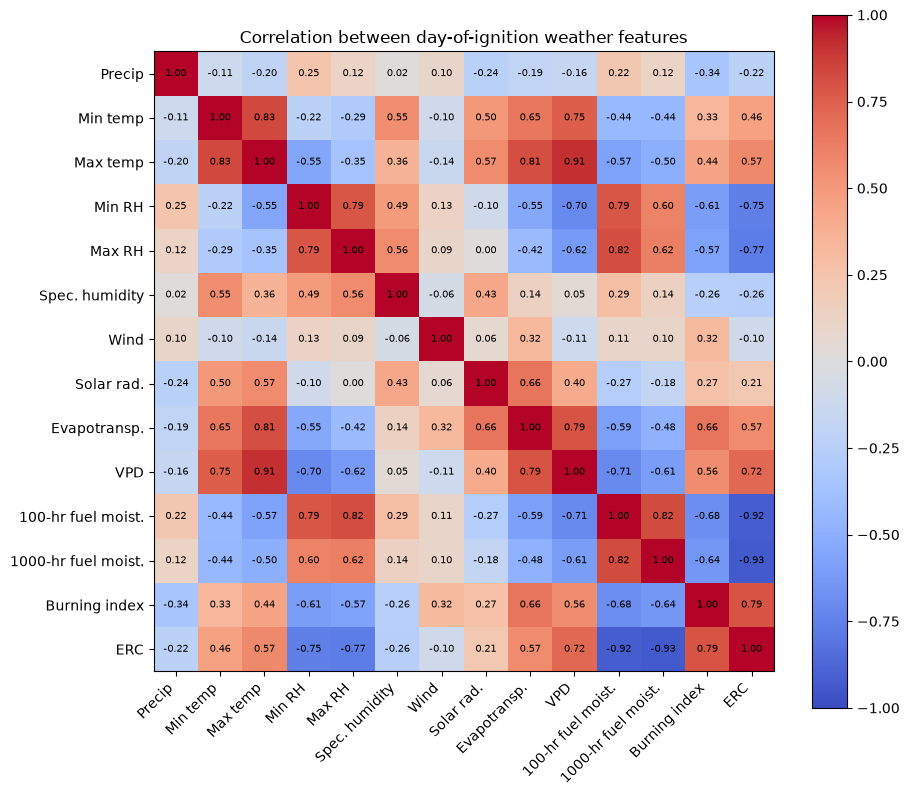

1000-hr fuel moist. ↔ ERC   -0.93
100-hr fuel moist. ↔ ERC    -0.92
Max temp ↔ VPD               0.91
dtype: float64

In [35]:
wx = [c for c in ["pr", "tmmn", "tmmx", "rmin", "rmax", "sph", "vs", "srad", "etr", "vpd", "fm100", "fm1000", "bi", "erc"] if c in df.columns]
corr = df[wx].corr()

short = {
    "pr": "Precip", "tmmn": "Min temp", "tmmx": "Max temp", "rmin": "Min RH", "rmax": "Max RH",
    "sph": "Spec. humidity", "vs": "Wind", "srad": "Solar rad.", "etr": "Evapotransp.",
    "vpd": "VPD", "fm100": "100-hr fuel moist.", "fm1000": "1000-hr fuel moist.",
    "bi": "Burning index", "erc": "ERC",
}
labels = [short.get(c, c) for c in wx]

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(wx)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(wx)), labels)
for i in range(len(wx)):
    for j in range(len(wx)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im)
ax.set_title("Correlation between day-of-ignition weather features")
save("08_weather_correlation"); plt.show()

# Pairs that carry nearly the same information
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = pairs[pairs.abs() > 0.85].sort_values(key=abs, ascending=False)
strong.index = [f"{short[a]} ↔ {short[b]}" for a, b in strong.index]
strong.round(2)


**Notes:** Day-of-ignition weather features form three correlated groups: (1) fuel dryness: energy release component (ERC), burning index (BI), and 100-hr/1000-hr dead fuel moisture (ERC vs. 1000-hr fuel moisture r = −0.93, partly because ERC is calculated from fuel moisture); (2) heat: max/min temperature, vapor pressure deficit (VPD), and reference evapotranspiration (max temperature vs. VPD r = 0.91); and (3) humidity: min/max relative humidity, closely linked to fuel moisture. Wind speed and precipitation are largely independent of the others. Because correlated features split credit in SHAP and permutation importance, we will also measure grouped importance by shuffling each group together.portance.

## 9. How much is missing in the model features?

In [36]:
miss = df[sets["model3_all"]].isna().mean()
print(f"{(miss > 0).sum()} of {len(miss)} features have any missing values; max = {miss.max():.1%} ({miss.idxmax()})")

9 of 86 features have any missing values; max = 2.4% (NDVI-1day)


## Summary

- **Class balance:** Highly imbalanced. A = 27,279 (62.6%), B = 13,678 (31.4%), C = 1,693 (3.9%), D-E = 591 (1.4%), F-G = 320 (0.7%). A model that always guesses "A" would be 63% accurate, so we use macro-F1 and balanced accuracy.
- **Where large fires cluster:** Large fires occur statewide. The count is highest in Southern California, largely because more fires start there. Northern California (Klamath/North Coast) and the southern Sierra have fewer fires but a higher share of the very largest (F-G). The Central Valley has many small fires and few large ones. *(Confirm with the large-fire rate map.)*
- **Strongest-looking features from section 4:** Fuel and air dryness. Energy release component rises (60 → 73) and vapor pressure deficit rises (1.6 → 2.2 kPa) from A to F-G, while 100-hr/1000-hr fuel moisture and minimum humidity fall. Elevation and slope also rise for larger fires. Wind speed shows no trend.
- **Peak month for large fires:** July has the most fires (~8,600), but August has the highest share that become large (~3.6%). There's a small secondary bump in December (~1.5%), possibly from Santa Ana winds.
- **Land cover types with the highest large-fire share:** Grassland (6.6%) and shrub/scrub (4.9%), versus a ~2.1% average. More developed land means a lower share.
- **South- vs north-facing slopes:** Flat ground (44% of fires) rarely produces large fires (1.0%). On slopes: south 3.4%, east/west 3.2%, north 2.4%. Having a slope matters more than its direction. Flat ground was initially misrecorded as north-facing, and we fixed it.
- **Redundant weather pairs:** ERC ↔ 1000-hr fuel moisture (r = −0.93), ERC ↔ 100-hr fuel moisture (−0.92), max temperature ↔ VPD (0.91). Wind speed and precipitation stand alone.
- **Cross-validation folds:** 5 location-based folds of about 8,700 fires each, with 50–77 F-G fires per fold.
- **Missing values:** Minimal (max 2.4%, NDVI the day before ignition), filled with the training median.
- **Open issue:** Cheatgrass cover uses 255 as a hidden "no data" code that appears mostly for small fires. Check it and likely remove it before modeling.